# 02 · Validity checks

**Goal:** before estimating any effect, check that the experiment itself can be trusted.

1. **Sample ratio mismatch (SRM):** do the observed arm sizes match the designed 1/3-1/3-1/3 split?
2. **Covariate balance:** do pre-treatment customer characteristics look the same across arms?

If either check failed, the effect estimates in notebook 03 could be biased no matter how carefully they are computed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hillstrom.data import load_customers
from hillstrom.plots import ARM_COLORS, ARM_LABELS, TEXT_SECONDARY, apply_style, save_figure
from hillstrom.validity import balance_table, srm_test

pd.set_option("display.float_format", "{:,.4f}".format)
apply_style()

df = load_customers()

## 1. Sample ratio mismatch

An SRM means the split that happened is not the split that was designed, which usually points to a bug in assignment or data logging (for example, some customers in one arm dropped out of the data). When that happens, the arms are no longer comparable and the experiment should not be analysed as-is.

**Test:** chi-square goodness-of-fit of the three arm counts against equal thirds (2 degrees of freedom). One test covers all three arms at once; pairwise binomial tests would need three tests and a multiple-comparison fix.

**Threshold:** SRM checks are usually flagged at p < 0.001 rather than 0.05. The check is run routinely on every experiment, so a 0.05 threshold would raise a false alarm on 1 in 20 healthy experiments, while a real assignment bug typically produces a far smaller p-value.

In [2]:
counts = df["arm"].value_counts().sort_index()
srm = srm_test(counts.to_numpy(), [1 / 3, 1 / 3, 1 / 3])

pd.DataFrame(
    {"observed": srm.counts, "expected": srm.expected, "observed_share": srm.counts / srm.counts.sum()},
    index=counts.index,
).style.format({"observed": "{:,.0f}", "expected": "{:,.1f}", "observed_share": "{:.4f}"})

,observed,expected,observed_share
arm,,,
control,"21,306","21,333.3",0.3329
mens,"21,307","21,333.3",0.3329
womens,"21,387","21,333.3",0.3342


In [3]:
print(f"chi2 = {srm.chi2:.3f}, p = {srm.p_value:.3f}")

chi2 = 0.203, p = 0.904


**Result:** the largest deviation from the expected count is about 50 customers out of ~21,300 per arm, and p is far above 0.001. There is no sign of a sample ratio mismatch.

What this does *not* show: SRM only checks group sizes. A randomization bug that kept sizes equal but sorted customers into arms by some characteristic would pass this test. The balance check below covers that case.

## 2. Covariate balance

Randomization should make the arms look alike on every characteristic measured *before* the emails were sent. For each email arm vs No E-Mail, the table reports the **standardized mean difference (SMD)** of each pre-treatment variable:

$$\text{SMD} = \frac{\bar{x}_{\text{email}} - \bar{x}_{\text{control}}}{\sqrt{(s^2_{\text{email}} + s^2_{\text{control}})/2}}$$

Categorical variables (`zip_code`, `channel`, `history_segment`) are split into one 0/1 indicator per level. A common rule of thumb treats |SMD| < 0.1 as negligible imbalance.

**Why SMD and not a t-test per variable:** a p-value mostly reflects sample size. With ~21,000 customers per arm, a trivially small difference can be "significant", and with a small sample a large one can be missed. SMD measures the *size* of the difference, which is what could bias the results. Also, in a randomized experiment any difference between arms is by construction due to chance, so a significance test would only be testing a null we already know is true.

In [4]:
covariates = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel", "history_segment"]
balance = balance_table(df, covariates)
balance

,mens,womens
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026
zip_code=Rural,0.0137,0.0040
zip_code=Suburban,-0.0117,-0.0011
zip_code=Urban,0.0020,-0.0018
channel=Multichannel,-0.0042,-0.0053
channel=Phone,-0.0083,0.0086


In [5]:
print(f"Largest |SMD|: {balance.abs().max().max():.4f}")

Largest |SMD|: 0.0164


**How big would chance differences be?** Under randomization, the SMD of a variable has a standard deviation of roughly $\sqrt{1/n_{\text{email}} + 1/n_{\text{control}}}$, about 0.0097 here. So about 95% of SMDs should fall within ±0.019 by chance alone. The plot shows that band in gray, next to the ±0.1 rule-of-thumb threshold.

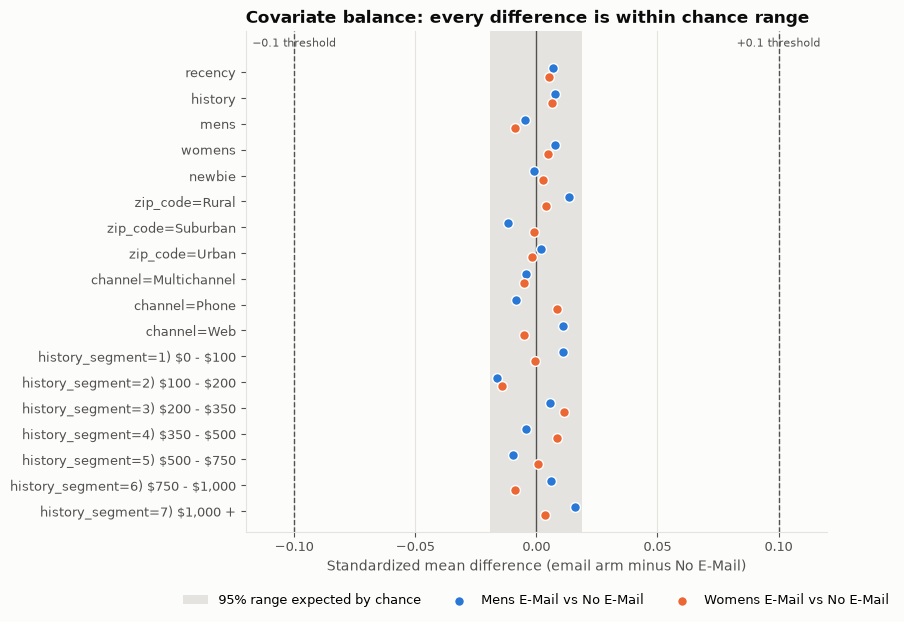

In [6]:
n = df["arm"].value_counts()
chance_band = 1.96 * np.sqrt(1 / n["mens"] + 1 / n["control"])  # same to 4 decimals for womens

fig, ax = plt.subplots(figsize=(7.5, 6.5))
y = np.arange(len(balance))[::-1]

ax.axvspan(-chance_band, chance_band, color="#e4e3df", lw=0, label="95% range expected by chance")
ax.axvline(0, color=TEXT_SECONDARY, lw=1)
for x in (-0.1, 0.1):
    ax.axvline(x, color=TEXT_SECONDARY, lw=1, ls="--")
ax.text(0.1, y.max() + 0.9, "+0.1 threshold", ha="center", va="bottom", fontsize=8, color=TEXT_SECONDARY)
ax.text(-0.1, y.max() + 0.9, "−0.1 threshold", ha="center", va="bottom", fontsize=8, color=TEXT_SECONDARY)

for offset, arm in [(0.17, "mens"), (-0.17, "womens")]:
    ax.scatter(
        balance[arm], y + offset, s=50, color=ARM_COLORS[arm], edgecolor="white", linewidth=1,
        zorder=3, label=f"{ARM_LABELS[arm]} vs No E-Mail",
    )

ax.set_yticks(y, balance.index)
ax.set_ylim(-0.8, y.max() + 1.6)
ax.set_xlim(-0.12, 0.12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Standardized mean difference (email arm minus No E-Mail)")
ax.set_title("Covariate balance: every difference is within chance range", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
save_figure(fig, "02_covariate_balance")
plt.show()

**Result:** every SMD is below 0.02 in absolute value, five times smaller than the 0.1 threshold, and all of them sit inside the range expected from chance alone. The arms are balanced on recency, past spend, purchase history, location, channel and new-customer status.

## Takeaways

- **No sample ratio mismatch** (p ≈ 0.90): the arm sizes match the designed equal split.
- **Covariates are balanced**: the largest standardized difference is about 0.016, consistent with chance.
- Together these support analysing the experiment as a clean randomized test: in notebook 03, simple differences in means between arms are unbiased estimates of each email's effect.

**What we cannot claim:** balance can only be checked on *observed* variables. Randomization is what protects against imbalance on unobserved ones; these checks show no evidence that randomization failed, which is all that any balance check can show.